# EDA: AI Employment Impact

*Josh Duchene — SEIS 631*


The goal of this project is to examine the relationship between exposure to AI and changes in employment, by occupation, in the US. This analysis is being conducted using BLS (Bureau of Labor Statistics) data.

The general question I'll be testing is this: Have occupations that are highly exposed to AI seen greater (or lesser) changes in total employment over the past few years compared to occupations that are less exposed, or is there no difference between those with higher/lower exposure?

## 1. Provenance & scope

1. I got the data from the BLS website.

    These are the data sources I plan to use:

    * https://www.bls.gov/emp/publications/ai-exposure-categories.htm

        gives the AI-exposure levels of the ~830 job categories included.

        The exposure ratings are Low, Moderate, High, and Very High. The website cites 5 scholarly articles that were used to informed this ranking. It seems like they did a pretty thorough job trying to come up with these ratings, but, it's obviously a bit speculative and subjective. But the BLS does survey actual businesses, so my assumption is essentially, who is more likely than the BLS to have gathered decent data/knowledge on how/where AI is currently being deployed.

        I read it into python as `ai_exposure_ratings`

    * https://www.bls.gov/oes/tables.htm

        This page has links to the Occupational Employment and Wage Statistics (OEWS) Tables

        It has a file for each year, giving employment numbers, median wages, etc by job title. it has 830 job titles, and each of those has an industry code, (e.g 12-3456), where each digit provides a more detailed breakdown, meaning I will be able to group/aggregate the data to a more useful level, while still having access to the lower level data. The data downloads actually include rows for these aggregated values as well, so when I use the data, I end up filtering it to only include rows at the lowest level.

        It has data for each year, but I only use 2022 and 2025. I chose 2025 because it's the latest year available, and I chose 2022 because Chat GPT became available to the public in Nov. 2022, so May 2022 seems like a good 'before' point to use. 

        I read this data into python as `data_2022` and `data_2025`, and merge these together, creating `employment_data`

    <!-- * https://www.bls.gov/oes/2025/may/oes_stru.htm

        Gives the breakdown of the occupation codes, at the high level, and all subsequent lower levels. Here's the first few rows to give an idea:

            11-0000 Management Occupations

            11-1000 Top Executives

            11-1010 Chief Executives

            11-1011 Chief Executives

            11-1020 General and Operations Managers

            11-1021 General and Operations Managers

            11-1030 Legislators

            11-1031 Legislators

            11-2000 Advertising, Marketing, Promotions, Public Relations, and Sales Managers -->


2. Each row represents data for one occupational grouping. So, as a made up example, there might be a row for 'Data Scientists & Data Analysts', another row for 'Data Scientists', and another for 'Data Analysts'.

3. How big is it, and what time period / geography / population does it cover?

    The AI exposure dataset has 831 rows, and the employment dataset has 1400 rows after merging the 2022 and 2025 data, but this drops to 829 rows after filtering by aggregation level.


4. What could this data plausibly generalize to — and what tempting question can it *not* answer?

    This data comes from the BLS, and is meant to represent the totality of employment in the US. So in theory, it is already as general as it gets. I suppose it could be tempting to generalize to other countries, but the labor markets in different countries are very different, so I don't think that would be warranted. The AI exposure ratings are somewhat based on actual reported use of AI, but they're also somewhat speculative, so I suppose it could be tempting to assume these ratings are 100% correct, and that nothing in the AI landscape will change in the next few years.   


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the data

First, I load in the employment data from the years 2022 and 2025. Once they're loaded in, I will merge the two datasets together.

In [2]:
def read_and_prepare_data(file_path, suffix=''):
    df = pd.read_csv(file_path, sep='\t')
    # Looking very breifly at a few things just to make sure the data was read in properly.
    assert df['AREA'].eq(99).all(), \
        'The data should only contain national-level entries, indicated by AREA equaling 99.'

    df['TOT_EMP'] = df['TOT_EMP'].str.replace(',', '').astype(int)

    cols_to_keep = ['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE']
    df = df[cols_to_keep]
    # renaming the columns to include the suffix for consistency with the year-specific data
    df = df.rename(columns={col: col + suffix for col in ['TOT_EMP', 'EMP_PRSE']})

    return df


data_2025 = read_and_prepare_data('data/national_M2025_dl.tsv', '_2025')
print('Shape of the 2025 data:', data_2025.shape)
display(data_2025.dtypes)

data_2022 = read_and_prepare_data('data/national_M2022_dl.tsv', '_2022')
print('Shape of the 2022 data:', data_2022.shape)


Shape of the 2025 data: (1401, 5)


OCC_CODE             str
OCC_TITLE            str
O_GROUP              str
TOT_EMP_2025       int64
EMP_PRSE_2025    float64
dtype: object

Shape of the 2022 data: (1402, 5)


# Merging the 2025 and 2022 data

Merging the two datasets on ['OCC_CODE', 'OCC_TITLE', 'O_GROUP']. In theory, merging on OCC_CODE alone is sufficient, but merging on all 3, and seeing that new rows don't end up getting created, serves as an implicit validation step, verifying that the categorization didn't change between 2022 and 2025.

The only other rows that we kept from the original datasets were the `TOT_EMP` and `EMP_PRSE` columns, so after the merge, we end up with 2 versions of these columns, 1 from each dataset.

In terms of the merge, the 2025 and 2022 datasets had 1401 and 1402 rows, and the merged outcome had 1403 rows.

1400 of the rows matched perfectly, and only 3 were unmatched.
* 2 rows were in the 2022 data, but not 2025
    - These rows were the 'legislators' category. For whatever reason, this occupation is just not listed in the 2025 data.
* 1 row was in the 2025 data, but not 2022:
    - This was the 'Prosthodontists' category, with ~900 total employment in the US.

With 1400 rows matched, and only 3 unmatched, it's fine for the analysis to simply drop the unmatched rows.

In [3]:
employment_data = pd.merge(
    data_2022,
    data_2025,
    on=['OCC_CODE', 'OCC_TITLE', 'O_GROUP'],
    how='outer',
    validate='one_to_one',
    indicator=True)

# print the shapes of the 2022 and 2025 data
print('Shape of the 2022 data:', data_2022.shape)
print('Shape of the 2025 data:', data_2025.shape)
print('Shape of the merged data:', employment_data.shape)
display(employment_data['_merge'].value_counts())

print('There are only 3 rows that do not match between the 2022 and 2025 data. '
      'They are shown below:')
display(employment_data[employment_data['_merge'] != 'both'])

# Drop the unmatched rows
employment_data = employment_data[employment_data['_merge'] == 'both'].drop(columns=['_merge'])
print('Shape of the data after dropping unmatched rows:', employment_data.shape)


Shape of the 2022 data: (1402, 5)
Shape of the 2025 data: (1401, 5)
Shape of the merged data: (1403, 8)


_merge
both          1400
left_only        2
right_only       1
Name: count, dtype: int64

There are only 3 rows that do not match between the 2022 and 2025 data. They are shown below:


,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,_merge
7,11-1030,Legislators,broad,42890.0,2.1,NaN,NaN,left_only
8,11-1031,Legislators,detailed,42890.0,2.1,NaN,NaN,left_only
516,29-1024,Prosthodontists,detailed,NaN,NaN,870.0,27.6,right_only


Shape of the data after dropping unmatched rows: (1400, 7)


### Now, reading in the dataset with the AI Exposure ratings

In [4]:
cols_to_keep = [
    '2025 National Employment Matrix title',
    '2025 National Employment Matrix code',
    'Employment, 2025',
    'Relative AI exposure',
]

# The data came in an excel file, and when I saved it as a tsv file,
# all of the dashes were turned to this: �. And it was causing issues
# in pandas. So, I just made a copy of the file, and manually did replace
# all to change all of the � back to - .

ai_exposure_ratings = pd.read_csv(
    'data/ai-exposure-categories-fixed_encodings.tsv',
    sep='\t',
    skiprows=1,  # The first row is the title of the whole worksheet
    nrows=831,  # The rows beyond this are just a footnote
    usecols=cols_to_keep)

# Fixing the 'Employment, 2025' column to be numeric by removing commas and converting to float
# Additionally, the employment numbers are given in thousands,
#  so multiplying by 1000 to get the actual numbers
ai_exposure_ratings['Employment, 2025'] = (
    ai_exposure_ratings['Employment, 2025']
    .str.replace(',', '')
    .astype(float)
    * 1000
)

# Verifying that the total employment in 2025 is within the expected range
assert 1e8 <= ai_exposure_ratings['Employment, 2025'].sum() <= 2e8, \
    'Expected total employment in 2025 to be between 100 and 200 million'

display(ai_exposure_ratings.tail(10))

,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure
821,"Laborers and freight, stock, and material move...",53-7062,2940300.0,Low
822,Machine feeders and offbearers,53-7063,41800.0,Low
823,"Packers and packagers, hand",53-7064,555500.0,Low
824,Stockers and order fillers,53-7065,2804300.0,Moderate
825,Gas compressor and gas pumping station operators,53-7071,3500.0,Low
826,"Pump operators, except wellhead pumpers",53-7072,9800.0,Moderate
827,Wellhead pumpers,53-7073,18400.0,Low
828,Refuse and recyclable material collectors,53-7081,156400.0,Low
829,"Tank car, truck, and ship loaders",53-7121,12800.0,Low
830,"Material moving workers, all other",53-7199,27800.0,Low


### Deciding on the level of aggregation for the analysis

So before digging too much further into the data itself, I need to decide what level of aggregation to do the analysis at. The occupation codes are given as 6 digit codes, and each subsequent digit adds a level of specificity. The AI exposure ratings are provided at the most detailed level, so I would be able to use the most granular data, or aggregate it up if the low-level data is too messy.


I was expecting it to be a deicison with no clear 'correct' answer, but, as it turns out, the decision is actually relatively easy to make. Essentially, if I were going to aggregate the data up a level, but the AI exposure ratings are at the lowest level, I'd need some way of deciding what label to assign to the new, aggregated groups. This would be easy if all of the occupations in a given group had the same labels, but it would be a lot more involved if there were mixed labels, and something I would only want to do if it was pretty rare for the labels to be mixed.

And so, in the next cell I look into this, to see how often there are mixed labels. And it turns out that about 20% of the aggregated groups would be created from occupations with mixed labels, and 40% of all occupations are in one of the groups with mixed labels. So that's a lot of information that I would basically be losing if I decided to go the aggregation route, so I'm going to be sticking with the lowest level for my analysis.

In [5]:
detailed = ai_exposure_ratings.copy()
# replacing the final digit of the code with a 0, to create a broad code
detailed["broad_code"] = detailed["2025 National Employment Matrix code"].str[:-1] + "0"

# how many distinct labels per broad group?
agreement = detailed.groupby("broad_code")["Relative AI exposure"].nunique().rename("n_labels")
print(agreement.value_counts())
percent_with_mixed = (agreement > 1).mean()
print("Percent of broad groups with mixed labels: "
      f"{percent_with_mixed:.2%}")
print()

# how many occupations fall into broad groups with mixed labels?
detailed = detailed.merge(agreement, on="broad_code")
print(detailed['n_labels'].value_counts())
percent_with_mixed = (detailed['n_labels'] > 1).mean()
print("Percent of occupations within broad groups with mixed labels: "
      f"{percent_with_mixed:.2%}")

display(detailed.query('n_labels > 1'))


n_labels
1    360
2     83
3     13
Name: count, dtype: int64
Percent of broad groups with mixed labels: 21.05%

n_labels
1    493
2    267
3     71
Name: count, dtype: int64
Percent of occupations within broad groups with mixed labels: 40.67%


,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure,broad_code,n_labels
3,Marketing managers,11-2021,421600.0,Very high,11-2020,2
4,Sales managers,11-2022,650100.0,High,11-2020,2
5,Public relations managers,11-2032,80800.0,Very high,11-2030,2
6,Fundraising managers,11-2033,48800.0,High,11-2030,2
7,Administrative services managers,11-3012,279000.0,Moderate,11-3010,2
...,...,...,...,...,...,...
823,"Packers and packagers, hand",53-7064,555500.0,Low,53-7060,2
824,Stockers and order fillers,53-7065,2804300.0,Moderate,53-7060,2
825,Gas compressor and gas pumping station operators,53-7071,3500.0,Low,53-7070,2
826,"Pump operators, except wellhead pumpers",53-7072,9800.0,Moderate,53-7070,2


So now that I've decided I'm using the detailed occupational codes for the analysis, I need to filter `employment_data`, as this dataset includes rows for the aggregated occupation categories. The filtering itself is just 1 line of code, but I want to do a quick bit of EDA first to show that this approach is correct.

In [6]:
# EDA on aggregation levels

# the O_GROUP column shows the aggregation level in the data. 
# The possible values are total, major, minor, broad, or detailed.
display('Showing the value counts of O_GROUP')
display(employment_data['O_GROUP'].value_counts())

# Showing the total employment for each aggregation level. 
display('Showing the total 2025 employment for each of the O_GROUP levels.')
display('The main thing to notice is that they all essentially sum up to the same total.')
display(employment_data.groupby('O_GROUP')['TOT_EMP_2025'].sum())

display('Here is an example of one branch of the occupational hierarchy')
display('to help visualize how the aggregation levels work')
display(
    employment_data
    [['OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP_2025']]
    .query('OCC_CODE.str.startswith("11-20") or OCC_CODE.str.startswith("11-0000")')
)


'Showing the value counts of O_GROUP'

O_GROUP
detailed    829
broad       454
minor        94
major        22
total         1
Name: count, dtype: int64

'Showing the total 2025 employment for each of the O_GROUP levels.'

'The main thing to notice is that they all essentially sum up to the same total.'

O_GROUP
broad       155481690.0
detailed    155480970.0
major       155495730.0
minor       155494840.0
total       155495730.0
Name: TOT_EMP_2025, dtype: float64

'Here is an example of one branch of the occupational hierarchy'

'to help visualize how the aggregation levels work'

,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP_2025
1,11-0000,Management Occupations,major,11132700.0
9,11-2000,"Advertising, Marketing, Promotions, Public Rel...",minor,1167460.0
10,11-2010,Advertising and Promotions Managers,broad,21470.0
11,11-2011,Advertising and Promotions Managers,detailed,21470.0
12,11-2020,Marketing and Sales Managers,broad,1032320.0
13,11-2021,Marketing Managers,detailed,395240.0
14,11-2022,Sales Managers,detailed,637080.0
15,11-2030,Public Relations and Fundraising Managers,broad,113670.0
16,11-2032,Public Relations Managers,detailed,74850.0
17,11-2033,Fundraising Managers,detailed,38810.0


So the main thing to notice in the previous cell is that summing the employment numbers within each O_GROUP, we get the same number, and that number is ~155 million, which is what the total employment number in the US in May 2025 was. So this means we can choose whichever O_GROUP level we want, filter out the rest, and the resulting data will represent the overall employment in the US.

And since we are doing the analysis at the lowest level of aggregation, the O_GROUP we'll be using is 'detailed'.



In [7]:
detailed_employment_data = employment_data.query('O_GROUP == "detailed"').copy()
assert detailed_employment_data['O_GROUP'].eq('detailed').all(), \
    "Not all rows have O_GROUP equal to 'detailed'"

detailed_employment_data = detailed_employment_data.drop(columns=['O_GROUP'])
display(detailed_employment_data.head())

,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025
4,11-1011,Chief Executives,199240.0,0.9,204350.0,3.1
6,11-1021,General and Operations Managers,3376680.0,0.3,3503020.0,0.3
11,11-2011,Advertising and Promotions Managers,22010.0,3.1,21470.0,3.9
13,11-2021,Marketing Managers,328570.0,1.1,395240.0,0.8
14,11-2022,Sales Managers,536390.0,2.8,637080.0,1.1


### Merging the 2 datasets

Now, with both datasets being at the same level of aggregation, we merge them together.

There are 829 rows in the detailed_employment_data, and 831 in the ai_exposure_ratings. When I merge the 2 datasets, all 829 rows match up, with the 2 extra rows remaining unmatched. I simply drop these 2 rows.

And then to validate the merge, I verify that the occupation labels from the two datasets match, and I verify that the 2025 employment numbers from the 2 datasets roughly match. And for the most part, they do align very well. There are a few outliers, but since the two measurements don't come from the same source, and might not even have been measured at the same point in 2025, so we would expect some discrepancies.

In [8]:
print('Starting shape for detailed_employment_data:', detailed_employment_data.shape)
print('Starting shape for ai_exposure_ratings:', ai_exposure_ratings.shape)

merged_data = detailed_employment_data.merge(
    ai_exposure_ratings,
    left_on='OCC_CODE',
    right_on='2025 National Employment Matrix code',
    how='outer',
    validate='one_to_one',
    indicator=True,
)

# Only 2 rows didn't match in the merge, and they represented a very
# small portion of the data, so it's safe to just drop those 2 rows.
print('showing _merged value_counts, and the rows that did not match')
display(merged_data['_merge'].value_counts())
display(merged_data[merged_data['_merge'] != 'both'])
merged_data = merged_data[merged_data['_merge'] == 'both'].drop(columns=['_merge'])


# Validating the merge
assert (
    merged_data['OCC_TITLE'].str.lower()
    == merged_data['2025 National Employment Matrix title'].str.lower()
).all(), "OCC_TITLE and 2025 National Employment Matrix title do not match"


# Getting an absolute percent difference between Employment, 2025 and TOT_EMP_2025
# `Employment, 2025` comes from the AI exposure dataset, and I'm not planning on using
#  it in the analysis. But, I still want to check to make sure it's roughly consistent 
# with TOT_EMP_2025 from the employment dataset, as a further validation step,
#  to confirm that am I merging the datasets correctly

# And looking at the distribution of the absolute percent difference, there are a few
#  outliers, but overall the absolute percent difference seems reasonable. The numbers
#  don't come from the same source, and might not even have been measured at the same
#  point in 2025, so we would expect some discrepancies.
merged_data['abs_percent_diff'] = (
    (merged_data['Employment, 2025'] - merged_data['TOT_EMP_2025']).abs()
     / merged_data[['TOT_EMP_2025', 'Employment, 2025']].mean(axis=1)
     * 100
)
print('Displaying absolute percent difference statistics between "Employment, 2025" and "TOT_EMP_2025":')
display(merged_data['abs_percent_diff'].describe())
merged_data = merged_data.drop(columns=['abs_percent_diff'])

# Dropping the redundant columns from the AI exposure dataset, now that the merge has been validated.
redundant_columns = [
    '2025 National Employment Matrix title',
    '2025 National Employment Matrix code',
    'Employment, 2025',
]
merged_data = merged_data.drop(columns=redundant_columns)

Starting shape for detailed_employment_data: (829, 6)
Starting shape for ai_exposure_ratings: (831, 4)
showing _merged value_counts, and the rows that did not match


_merge
both          829
right_only      2
left_only       0
Name: count, dtype: int64

,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025",Relative AI exposure,_merge
308,NaN,NaN,NaN,NaN,NaN,NaN,Prosthodontists,29-1024,1000.0,Low,right_only
559,NaN,NaN,NaN,NaN,NaN,NaN,Fishing and hunting workers,45-3031,28200.0,Low,right_only


Displaying absolute percent difference statistics between "Employment, 2025" and "TOT_EMP_2025":


count    829.000000
mean      14.147606
std       25.483409
min        0.000000
25%        1.843462
50%        4.980152
75%       14.813017
max      196.730382
Name: abs_percent_diff, dtype: float64

## Structure & quality

5. What are the important variables, and what type is each (categorical, continuous, datetime, text, ID)?

    The most important variables are `TOT_EMP_2022`, `TOT_EMP_2025` (These are ints), and `Relative AI exposure` (which is a categorical feature, taking the values [Very high, High, Moderate, Low])

    I create the columns `TOT_EMP_pct_change` and `TOT_EMP_abs_pct_change` eventually, as the (absolute) percent change between employment in 2022 and 2025 within a given occupation. 

    The other columns are `OCC_CODE` and `OCC_TITLE`, which are just labels for the occupation, and `EMP_PRSE_2022` and `EMP_PRSE_2025`, where PRSE stands for percent relative standard error values, and represent the uncertainty of the employment estimate. 

6. What's missing — and if nothing, how do you know? Completeness is a claim that must be earned: "no missing values (verified)" is real communication work. If something *is* missing, does it have a pattern?

    I validate below that there are no missing values.

7. Are there duplicates, impossible values, or suspicious encodings (999s, "unknown", mixed units)?
    
    I validate below that there are no duplicates, either across the entire row, or in the columns `OCC_CODE` or `OCC_TITLE`. 

    I validate that the employment columns are always nonnegative, and that all values of relative ai exposure are in the expected set of values ([Very high, High, Moderate, Low]).

    And the fact that the two datasets were merged on OCC_CODE, and the OCC_TITLE values from the 2 datasets matched every single time is its own sort of validation of those values.

8. What variables did the author create or transform, and why?

    All of the variables come straight from the BLS, so none of the variables are really *created* beyond the sense that the BLS has internal processes to create their statistics.


#### Describing the columns in the datasets

In [9]:
# The table created in this cell shows a summary of the columns,
# showing their dtype, how many unique values there are, some examples
# of the types of values (for categorical cols), and the observed min
# and max for numerical columns.

# Add compact details to help classify and describe columns.
def summarize_columns(df):
    inventory = pd.DataFrame(index=df.columns)
    inventory.index.name = "column"
    inventory["pandas_dtype"] = df.dtypes.astype(str)
    inventory["distinct_values"] = df.nunique(dropna=True)
    inventory["examples_or_levels"] = [
        df[column].dropna().unique()[:5].tolist()
        for column in df.columns
    ]

    numeric_columns = df.select_dtypes(include="number").columns
    inventory["observed_min"] = None
    inventory["observed_max"] = None
    inventory.loc[numeric_columns, "observed_min"] = df[numeric_columns].min()
    inventory.loc[numeric_columns, "observed_max"] = df[numeric_columns].max()

    return inventory


# Showing the detailed_employment_data dataset
print('Showing a sample of the merged_data dataset')
display(merged_data.sample(5, random_state=42))
print('Showing a brief of summary of the columns in the merged_data dataset')
display(summarize_columns(merged_data.copy()))


Showing a sample of the merged_data dataset


,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,Relative AI exposure
610,47-4090,Miscellaneous Construction and Related Workers,29880.0,5.5,28380.0,5.2,Moderate
458,39-4012,Crematory Operators,2930.0,10.8,2970.0,5.9,Moderate
290,27-3041,Editors,101430.0,1.4,91690.0,1.7,Very high
560,45-4011,Forest and Conservation Workers,6080.0,8.6,6050.0,6.4,Low
168,19-4061,Social Science Research Assistants,28720.0,1.6,30640.0,1.8,Very high


Showing a brief of summary of the columns in the merged_data dataset


,pandas_dtype,distinct_values,examples_or_levels,observed_min,observed_max
column,,,,,
OCC_CODE,str,829,"[11-1011, 11-1021, 11-2011, 11-2021, 11-2022]",None,None
OCC_TITLE,str,829,"[Chief Executives, General and Operations Mana...",None,None
TOT_EMP_2022,float64,809,"[199240.0, 3376680.0, 22010.0, 328570.0, 53639...",330.0,3640040.0
EMP_PRSE_2022,float64,125,"[0.9, 0.3, 3.1, 1.1, 2.8]",0.0,34.5
TOT_EMP_2025,float64,810,"[204350.0, 3503020.0, 21470.0, 395240.0, 63708...",220.0,4305810.0
EMP_PRSE_2025,float64,130,"[3.1, 0.3, 3.9, 0.8, 1.1]",0.0,35.0
Relative AI exposure,str,4,"[Very high, High, Moderate, Low]",None,None


### Validating the data

In [10]:
# validating the data

assert merged_data.notna().all(axis=None)

for col in ['OCC_CODE', 'OCC_TITLE']:
    assert merged_data[col].duplicated().sum() == 0, \
        'Duplicates present in column: ' + col
assert merged_data.duplicated().sum() == 0, 'Duplicates present in the merged data'


assert merged_data[['TOT_EMP_2022', 'TOT_EMP_2025']].ge(0).all(axis=None), \
    'Negative values present in TOT_EMP_2022 or TOT_EMP_2025'

assert merged_data['Relative AI exposure'].isin(['Very high', 'High', 'Moderate', 'Low']).all(), \
    'Invalid values present in Relative AI exposure'

print('Data validation completed successfully.')

Data validation completed successfully.


### Creating the percent change columns

In [11]:
# Creating the precent change column
merged_data['TOT_EMP_pct_change'] = (
    (merged_data['TOT_EMP_2025'] - merged_data['TOT_EMP_2022'])
    / merged_data['TOT_EMP_2022']
    * 100
)

# Creating an absolute percent change column
merged_data['TOT_EMP_abs_pct_change'] = merged_data['TOT_EMP_pct_change'].abs()


assert merged_data[['TOT_EMP_abs_pct_change', 'TOT_EMP_pct_change']].notna().all(axis=None), \
    'Missing values present in TOT_EMP_abs_pct_change or TOT_EMP_pct_change'

# I tried asserting that none of these values would be 0, assuming that it
# would be very unlikely. 2 of the 830 rows did report 0 change, however.
# It seems a bit odd and unlikely that this would happen by chance,
# but since it was just 2 rows, there's not something systematically going on,
# so it's really not a huge deal.
print('Showing the rows with 0 percent change')
display(merged_data[merged_data[['TOT_EMP_abs_pct_change', 'TOT_EMP_pct_change']].eq(0).any(axis=1)])

Showing the rows with 0 percent change


,OCC_CODE,OCC_TITLE,TOT_EMP_2022,EMP_PRSE_2022,TOT_EMP_2025,EMP_PRSE_2025,Relative AI exposure,TOT_EMP_pct_change,TOT_EMP_abs_pct_change
258,25-9021,Farm and Home Management Educators,8220.0,2.7,8220.0,5.9,High,0.0,0.0
585,47-2132,"Insulation Workers, Mechanical",25660.0,5.0,25660.0,5.2,Moderate,0.0,0.0


## Distributions & relationships

9. What does each key variable look like — shape, center, spread, outliers? *Do this with plots, but then also with words; do the work of interpretation for your audience.*
10. What are the two or three most important relationships in the data, shown and interpreted?
11. What's surprising here — what didn't the author expect to find?

### Showing the key variables

##### Looking at `Relative AI Exposure`

We start by looking at the distribution of Relative AI Exposure ratings. And it becomes instantly clear that the 4 ratings all have essentially the same number of occurrences, so it appears as though the occupations were just ordinally ranked based on AI exposure, and partitioned into 4 quartiles.

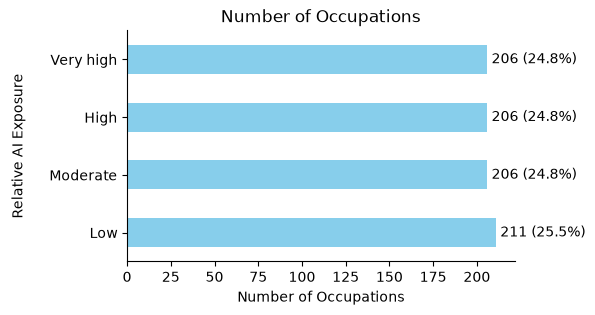

In [12]:
# plotting the distribution of Relative AI exposure among occupations
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

plt.figure(figsize=(5, 3))
counts = merged_data['Relative AI exposure'].value_counts().loc[reversed(exposure_ordering)]
counts.plot(
    kind='barh',
    color='skyblue'
)
for i, (count, pct) in enumerate(zip(counts, counts / counts.sum() * 100)):
    plt.text(count + 0.1, i, f' {count} ({pct:.1f}%)', va='center')
plt.xlabel('Number of Occupations')
plt.ylabel('Relative AI Exposure\n')
plt.title('Number of Occupations')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

##### Looking at Total Employment Numbers

Now, we look at the Total employment numbers (`TOT_EMP_2022` and `TOT_EMP_2025`). They have very similar distributions (as we'd expect), and it's a heavy right-skewed distribution. (Again, the skew is expected, because some professions, e.g. teachers, have a very large number of people, while others are quite niche).

So I plot the distributions normally first to demonstrate the skew, and then remake the plots using a log10 scale.

With the log-scale plot, we see a roughly symmetrical, bell-shaped distribution.

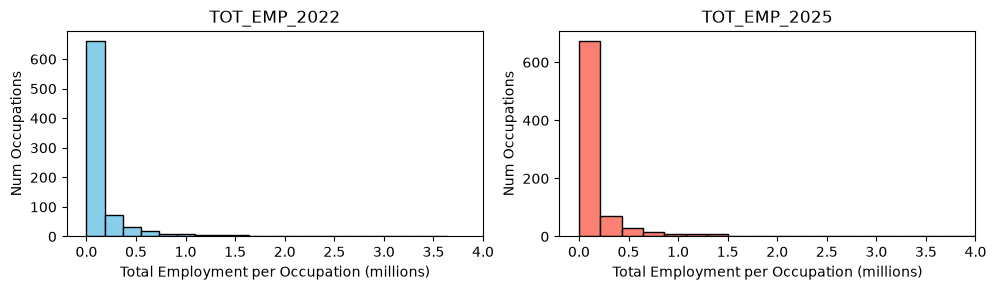

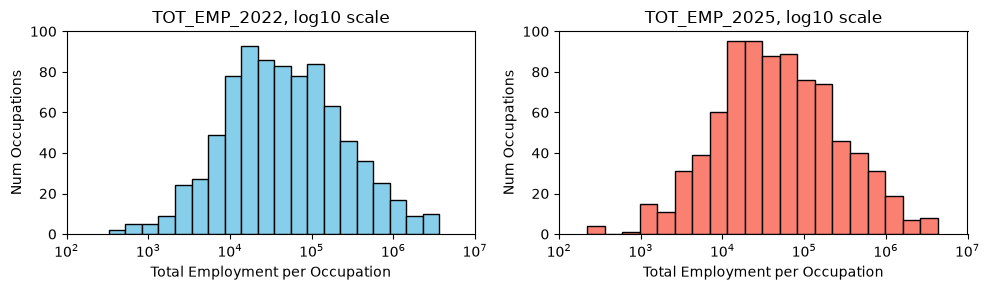

In [13]:
# make the plot again, but divide the values by 1 million first
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_2022'] / 1_000_000, bins=20, color='skyblue', edgecolor='black')
plt.xlim(-.2, 4)
plt.title('TOT_EMP_2022')
plt.xlabel('Total Employment per Occupation (millions)')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_2025'] / 1_000_000, bins=20, color='salmon', edgecolor='black')
plt.xlim(-.2, 4)
plt.title('TOT_EMP_2025')
plt.xlabel('Total Employment per Occupation (millions)')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()


# Plotting them on a log10 scale
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(np.log10(merged_data['TOT_EMP_2022']), bins=20, color='skyblue', edgecolor='black')
plt.ylim(0, 100)
plt.xlim(2, 7)
plt.xticks(range(2, 8), [f'$10^{i}$' for i in range(2, 8)])
plt.title('TOT_EMP_2022, log10 scale')
plt.xlabel('Total Employment per Occupation')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(np.log10(merged_data['TOT_EMP_2025']), bins=20, color='salmon', edgecolor='black')
plt.ylim(0, 100)
plt.xlim(2, 7)
plt.xticks(range(2, 8), [f'$10^{i}$' for i in range(2, 8)])
plt.title('TOT_EMP_2025, log10 scale')
plt.xlabel('Total Employment per Occupation')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()


#### To get a little more context, I also wanted to look at some of the largest and smallest occupations

In [14]:
# show the top 5 and bottom 5 occupations by the total employment in 2025
print('Showing the 5 occupations with the highest total employment in 2025')
display(merged_data[['OCC_TITLE', 'TOT_EMP_2025']].sort_values(by='TOT_EMP_2025', ascending=False).head(5))
print('Showing the 5 occupations with the lowest total employment in 2025')
display(merged_data[['OCC_TITLE', 'TOT_EMP_2025']].sort_values(by='TOT_EMP_2025', ascending=True).head(5))

Showing the 5 occupations with the highest total employment in 2025


,OCC_TITLE,TOT_EMP_2025
375,Home Health and Personal Care Aides,4305810.0
481,Retail Salespersons,3897860.0
426,Fast Food and Counter Workers,3854050.0
1,General and Operations Managers,3503020.0
324,Registered Nurses,3379720.0


Showing the 5 occupations with the lowest total employment in 2025


,OCC_TITLE,TOT_EMP_2025
738,"Patternmakers, Wood",220.0
683,Timing Device Assemblers and Adjusters,250.0
737,"Model Makers, Wood",280.0
44,Farm Labor Contractors,310.0
149,Industrial-Organizational Psychologists,790.0


##### Looking at `TOT_EMP_pct_change` and `TOT_EMP_abs_pct_change`

These distributions are right-skewed (especially the absolute value version). There are also a few pretty extreme outliers, that make the skew even more dramatic. The plots below are made without specifying the x-axis limits, so it's clear there are some major outliers that will need to be handled

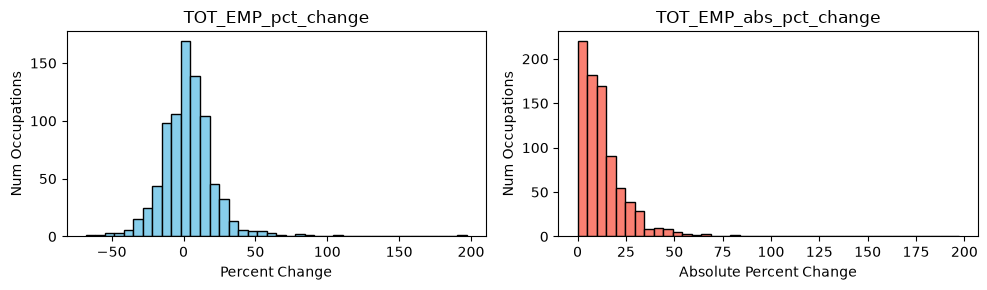

In [15]:
# make histograms of TOT_EMP_pct_change and TOT_EMP_abs_pct_change
# set the x axis limt to 75
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_pct_change'], bins=40, color='skyblue', edgecolor='black')
# plt.xlim(-75, 75)
plt.title('TOT_EMP_pct_change')
plt.xlabel('Percent Change')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_abs_pct_change'], bins=40, color='salmon', edgecolor='black')
# plt.xlim(-3, 75)
plt.title('TOT_EMP_abs_pct_change')
plt.xlabel('Absolute Percent Change')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()

Again, to get a little more context, I wanted to look at some of the top and bottom occupations in terms of largest absolute percent changes in employment


In [16]:
print('Showing the 5 occupations with the highest absolute percent change in employment')
display(merged_data.sort_values(by='TOT_EMP_abs_pct_change', ascending=False)[['OCC_TITLE', 'TOT_EMP_pct_change', 'TOT_EMP_2022', 'TOT_EMP_2025']].head(5))
print('Showing the 5 occupations with the lowest absolute percent change in employment')
display(merged_data.sort_values(by='TOT_EMP_abs_pct_change', ascending=True)[['OCC_TITLE', 'TOT_EMP_pct_change', 'TOT_EMP_2022', 'TOT_EMP_2025']].head(5))

Showing the 5 occupations with the highest absolute percent change in employment


,OCC_TITLE,TOT_EMP_pct_change,TOT_EMP_2022,TOT_EMP_2025
795,Taxi Drivers,197.033285,13820.0,41050.0
813,Passenger Attendants,105.378788,13200.0,27110.0
658,"Refractory Materials Repairers, Except Brickma...",86.206897,580.0,1080.0
490,Models,82.608696,2070.0,3780.0
420,"Cooks, Private Household",80.327869,610.0,1100.0


Showing the 5 occupations with the lowest absolute percent change in employment


,OCC_TITLE,TOT_EMP_pct_change,TOT_EMP_2022,TOT_EMP_2025
585,"Insulation Workers, Mechanical",0.000000,25660.0,25660.0
258,Farm and Home Management Educators,0.000000,8220.0,8220.0
758,"Extruding, Forming, Pressing, and Compacting M...",0.051073,58740.0,58770.0
251,Tutors,0.051434,174980.0,175070.0
534,"Production, Planning, and Expediting Clerks",0.061551,389920.0,390160.0


It's unsurprising that 3 of the 5 occupations with the largest percent changes were occupations with relatively small total employment, but the two with the largest are decent sized. Taxi drivers in particular is quite unexpected, as I would have assumed they were, if anything, in decline, as uber and lyft continue to take over. So this makes me think that it's more likely that somehow the classification of who counts as a taxi driver changed between 2022 and 2025, perhaps starting to count full-time uber/lyft drivers, or something like that.

There's no way to really know with the data we have, and it's probably not worth digging into it more deeply, but it does just add one more caveat to any conclusions we might draw, where the occupation categories might all be named the same things, but how people are apportioned might change somewhat. All that said, given how many of the occupations saw only incremental change between 2022 and 2025, it doesn't seem like this is something that occurs all that often, and it's probably not a huge concern to the analysis.

### Deciding how to handle the outliers

Even though the data comes from the BLS, and therefore is likely all pretty reliable, outliers can still end up skewing the results, and causing misleading conclusions.

So the next few cells are me trying to decide how to handle them.

First, I simply look at the values of various percentiles to get a sense of how much of the data is actually taking these extreme values. And as we can see, the highest value is a nearly 200% increase, while the 98th percentile is only 50%.  

In [17]:
# Looking at the distributions of the percent change columns
display(
    merged_data
    [['TOT_EMP_pct_change', 'TOT_EMP_abs_pct_change']]
    .describe(percentiles=[.05, .1, .25, .5, .75, .9, .95, .98])
)

,TOT_EMP_pct_change,TOT_EMP_abs_pct_change
count,829.000000,829.000000
mean,3.145392,13.288609
std,18.985722,13.912681
min,-68.055556,0.000000
5%,-24.683354,1.007234
10%,-16.818133,2.112503
25%,-7.221845,4.704938
50%,2.958904,10.108765
75%,12.012645,16.925734
90%,22.750426,27.792300


### Exploring the outliers, using various cutoffs

So the general idea of this next cell is to explore how many observations fall above certain percent change cutoffs, and to get a sense of whether the extreme outliers all tended to be small occupations, where a small change in absolute numbers could result in a large percent change.

My general takeaway is that most occupations showed relatively incremental change, with the 5th and 95th percentiles being roughly +/- 25% change. So I feel like it makes sense to just set those as caps, and just clip any values above that.

As I look at the numbers, there are 107/829 (12.9%) occupations with an absolute percent change over 25%, only 17/829 (2.1%) over 50%, and 5/829 (0.6%) above 75%, 50% seems like a reasonable cutoff. Additionally, looking at the descriptive stats of the occupations above each of those cutoffs, we see the average size of the occupations above the cutoff shrink rapidly, implying that as the outliers become more extreme, it is increasingly likely that it's happening in small occupations where a relatively small absolute change represents a huge percent change. And this makes treating them as outliers seem even more reasonable.

That said, because the PRSE (percent relative standard error) values, which represent the uncertainty of the employment estimate, is still actually pretty small (usually < 5%), even for the major outliers, that implies that these large changes are probably actually real, and not just flukes of the data. So that pushes me in the direction of still including them in the dataset, but just clipping their values at 50%.

In [18]:
# exploring the outliers, using various cutoffs
for cutoff in [25, 50, 75]:
    print('If using the cutoff of +/- {}%:'.format(cutoff))
    display(
        merged_data[['TOT_EMP_2022', 'EMP_PRSE_2022']]
        .groupby(
            merged_data['TOT_EMP_abs_pct_change']
            .gt(cutoff)
            .rename('Above Cutoff')
        )
        .agg(['count', 'mean', 'median'])
        .drop(columns=[('EMP_PRSE_2022', 'count'), ('EMP_PRSE_2022', 'median')])
    )

If using the cutoff of +/- 25%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 722  193601.454294  47660.0      2.968698
True                  107   75342.242991  16920.0      5.127103

If using the cutoff of +/- 50%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 812  181456.366995  44980.0      3.152833
True                   17   29370.588235  11110.0      7.758824

If using the cutoff of +/- 75%:


TOT_EMP_2022                         EMP_PRSE_2022
                    count           mean   median          mean
Above Cutoff                                                   
False                 824  179382.997573  43610.0       3.18932
True                    5    6056.000000   2070.0      12.80000

#### Creating the clipped versions of the percent change columns

In [19]:
# create clipped versions of the percent change columns
merged_data['TOT_EMP_pct_change_clipped'] = \
    merged_data['TOT_EMP_pct_change'].clip(lower=-50, upper=50)
merged_data['TOT_EMP_abs_pct_change_clipped'] = \
    merged_data['TOT_EMP_abs_pct_change'].clip(lower=0, upper=50)

# add some assertions to verify that the checks below would have
# failed for the nonclipped versions
assert not merged_data['TOT_EMP_pct_change'].between(-50, 50).all()
assert not merged_data['TOT_EMP_abs_pct_change'].between(0, 50).all()
# add some assertions to verify the clipping worked correctly
assert merged_data['TOT_EMP_pct_change_clipped'].between(-50, 50).all()
assert merged_data['TOT_EMP_abs_pct_change_clipped'].between(0, 50).all()

# A note:
# I had tried adding an assertion to make sure only 17 values equal 50% in the
# clipped absolute percent change column, because 17 is the expected number
# of clipped values. but there were actually 18, because apparently the occupation
# 'Rail Transportation Workers, All Other' had employment numbers of 2240 and 1120
# in 2022 and 2025 respectively, meaning it had a percent change of exactly -50%.
# So, this doesn't really affect anything, but it's just worth noting I guess.

# # assert (merged_data['TOT_EMP_abs_pct_change_clipped'] == 50).sum() == 17


#### Plotting the newly-created clipped percent change columns

The distributions after clipping the outliers look a lot better. The Percent Change distribution is roughly bell-shaped, with its mean slightly above 0. And the Absolute Percent Change distribution is clearly right-skewed, but not so dramatically that we'd need to plot it on a log scale to see what's going on.

The other obvious thing is the large spike at 50%, which is expected, because all of the clipped outliers end up in that single bin.

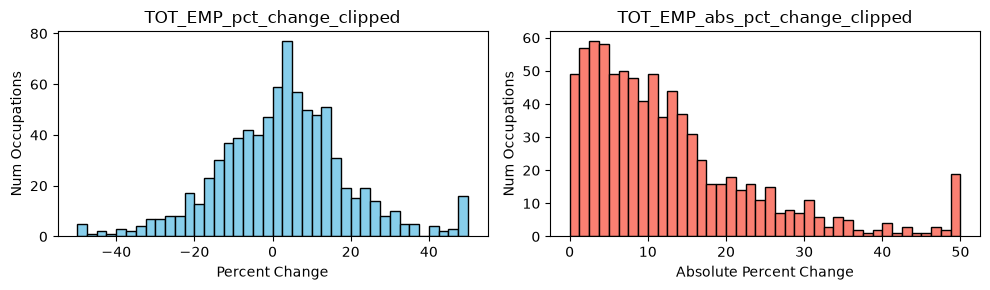

,TOT_EMP_pct_change_clipped,TOT_EMP_abs_pct_change_clipped
count,829.000000,829.000000
mean,2.736373,12.806113
std,16.714017,11.075223
min,-50.000000,0.000000
25%,-7.221845,4.704938
50%,2.958904,10.108765
75%,12.012645,16.925734
max,50.000000,50.000000


In [20]:
# change the pltos to use the clipped versions of the columns
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(merged_data['TOT_EMP_pct_change_clipped'], bins=40, color='skyblue', edgecolor='black')
# plt.xlim(-75, 75)
plt.title('TOT_EMP_pct_change_clipped')
plt.xlabel('Percent Change')
plt.ylabel('Num Occupations')

plt.subplot(1, 2, 2)
plt.hist(merged_data['TOT_EMP_abs_pct_change_clipped'], bins=40, color='salmon', edgecolor='black')
# plt.xlim(-3, 75)
plt.title('TOT_EMP_abs_pct_change_clipped')
plt.xlabel('Absolute Percent Change')
plt.ylabel('Num Occupations')

plt.tight_layout()
plt.show()

# Show .describe for the clipped columns
display(
    merged_data[['TOT_EMP_pct_change_clipped', 'TOT_EMP_abs_pct_change_clipped']]
    .describe()
)

## Preregistering My Planned Analysis

So the next step in my EDA is starting to look at the relationships between the variables.

And this portion of the EDA is where it could become very easy to see how the `Relative AI Exposure` ratings relate to the other variables, and end up using that knowledge to choose how to set up my future analysis in a way that maximizes the liklihood of me finding something. So I want to unofficially pre-register my planned analysis here, along with my reasoning, before actually delving into the EDA

* I've already decided that I'm going to be using the absolute percent change, instead of the signed version, as my key variable, because it would be expected that in occupations affected by AI, some would increase, while others would decrease, and those are both meaningful changes. And so I don't want to use the signed version, because then large increases and large decreases would just average each other out, and look like there was no effect.

* In terms of the AI Exposure categories I'm comparing, my plan is run 2 comparisons as my analysis:
    - Very High vs (all else)
    - Very High vs Low

    My reasoning for choosing these 2 tests is as follows:
    
    - Before looking at the data, my thoughts are that, in theory, very high vs low should be the starkest comparison. That is, if we see a difference at all, this is where we'd be most likely to see it.

    - But I'm also thinking that, since there's been a huge increase in data center production, and a lot of those manufacturing jobs are likely to be rated as having 'low exposure', that sector might actually be seeing a large increase right now. And, I guess maybe it's an open question of whether that'll be sustained growth, or merely transitory, like just until they've built enough. So, all that to say, I'm also planning to run another comparison where I combine the 3 lower categories together, and compare that to the 'Very High' exposure group, to help mitigate any effect this might have.

    - I'm planning to stick with just those 2 comparisons, unless the data makes it very clear that I need to revise. I could obviously make comparisons of like the top 2 and the bottom 2, or any other combination, but that would easily lead to the multiple hypothesis testing issue, and also just an interpretation blackhole (e.g. what would it mean if the top 3 saw greater change than the bottom 1, but the top 2 didn't see more change than the bottom 2, etc.).


### Looking at the relationships between the key variables


The key relationships between variables I'll want to look at are mostly centered around the Relative AI Exposure feature.

I'll want to compare `Relative AI Exposure` to `TOT_EMP_2025`, and to `TOT_EMP_abs_pct_change_clipped` and `TOT_EMP_pct_change_clipped`

I also want to just get a sense of what kinds of jobs are classified in each category, so I'm going to look at the largest occupations in each group

And I also want to compare `TOT_EMP_2025` and `TOT_EMP_abs_pct_change_clipped`. This one is less directly relevant to the eventual analysis, but since my analysis plan is to use `TOT_EMP_abs_pct_change_clipped` as the response variable, I'm curious to see if / to what extent smaller occupations do tend to show larger changes, because that would mean they would tend to have a larger influence on the outcome than larger occupations.



### Comparing log10(TOT_EMP_2025) and TOT_EMP_abs_pct_change_clipped

The scatter plot itself doesn't really show a strong relationship. Plotting a best fit line does show a slightly negative relationship, where larger occupations tended to see less absolute percentage change in employment. But the R^2 value is 0.0468, so that basically means the line explains nothing.

R-squared: 0.0468


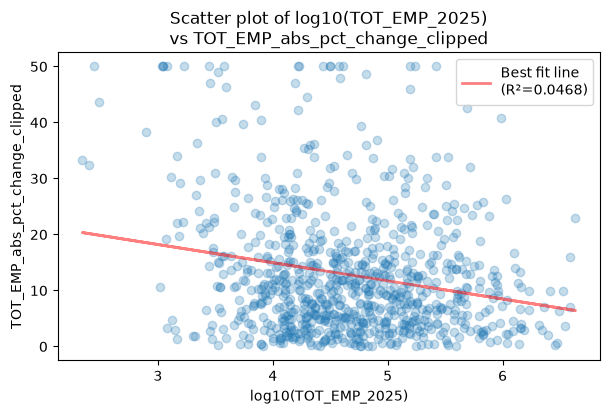

In [21]:
# make a scatter plot comparing tot_emp_2025 (log10) and TOT_EMP_abs_pct_change_clipped
import matplotlib.pyplot as plt
import numpy as np

# calculate and plot a best fit line on that graph as well
plt.figure(figsize=(7, 4))
plt.scatter(
    np.log10(merged_data['TOT_EMP_2025']),
    merged_data['TOT_EMP_abs_pct_change_clipped'],
    alpha=0.256
)
# calculate and plot a best fit line on that graph as well
# also calculate and print the R-squared value
x = np.log10(merged_data['TOT_EMP_2025'])
y = merged_data['TOT_EMP_abs_pct_change_clipped']
m, b = np.polyfit(x, y, 1)
r_squared = np.corrcoef(x, y)[0, 1]**2
print(f"R-squared: {r_squared:.4f}")

plt.plot(x, m*x + b, color='red', linewidth=2, alpha=.5,
         label=f'Best fit line\n(R²={r_squared:.4f})')
plt.xlabel('log10(TOT_EMP_2025)')
plt.ylabel('TOT_EMP_abs_pct_change_clipped')
plt.title('Scatter plot of log10(TOT_EMP_2025)\nvs TOT_EMP_abs_pct_change_clipped')
plt.legend()
plt.show()


In [22]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

# show the top 3 occupations by `TOT_EMP_2025` for each ai exposure level
for exposure in exposure_ordering:
    print(f"Top 3 occupations for {exposure} AI exposure:")
    top_3 = (
        merged_data
        .query('`Relative AI exposure` == @exposure')
        .sort_values('TOT_EMP_2025', ascending=False)
        [['OCC_TITLE', 'TOT_EMP_2025', 'Relative AI exposure']]
        .head(3)
    )
    display(top_3)
    print()


Top 3 occupations for Very high AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
481,Retail Salespersons,3897860.0,Very high
513,Customer Service Representatives,2595750.0,Very high
546,"Office Clerks, General",2464940.0,Very high



Top 3 occupations for High AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
1,General and Operations Managers,3503020.0,High
324,Registered Nurses,3379720.0,High
477,Cashiers,3089410.0,High



Top 3 occupations for Moderate AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
375,Home Health and Personal Care Aides,4305810.0,Moderate
426,Fast Food and Counter Workers,3854050.0,Moderate
824,Stockers and Order Fillers,2833810.0,Moderate



Top 3 occupations for Low AI exposure:


,OCC_TITLE,TOT_EMP_2025,Relative AI exposure
821,"Laborers and Freight, Stock, and Material Move...",2950280.0,Low
435,"Janitors and Cleaners, Except Maids and Housek...",2209760.0,Low
666,"Maintenance and Repair Workers, General",1529700.0,Low


### Showing descriptive stats of key variables, grouped by AI Exposure category

In [23]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    print(f"Column: {col}")
    desc = (
        merged_data
        .groupby('Relative AI exposure')
        [col].describe()
        .drop(columns=['min', 'max', 'count'])
        .loc[exposure_ordering]
    )
    display(desc.style.background_gradient(cmap='Greens', low=0, high=1).set_table_styles(
        [{'selector': 'thead', 'props': [('color', 'white')]},
         {'selector': 'tbody', 'props': [('color', 'white')]}]
    ))
    print("\n")

# display them all again, just without the coloring thing.
print('Just displaying the descriptive statistics without coloring, in case the coloring looks weird on github')
for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    print(f"Column: {col}")
    desc = (
        merged_data
        .groupby('Relative AI exposure')
        [col].describe()
        .drop(columns=['min', 'max', 'count'])
        .loc[exposure_ordering]
    )
    display(desc)
    print("\n")

Column: TOT_EMP_2025


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,238999.854369,468063.716038,29127.500000,74380.000000,208085.000000
High,186575.000000,450502.548927,15400.000000,40755.000000,145820.000000
Moderate,195976.941748,525748.509306,13042.500000,33745.000000,135525.000000
Low,130053.554502,328175.151134,10550.000000,27120.000000,101310.000000




Column: TOT_EMP_abs_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,11.648468,10.455087,3.895496,9.611734,15.777310
High,14.012844,12.279411,5.179369,10.288138,19.543609
Moderate,13.065786,11.184508,4.857379,10.144997,17.208292
Low,12.504669,10.233163,5.229954,10.596219,16.133306




Column: TOT_EMP_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,0.979708,15.642667,-7.624120,1.924780,10.084467
High,8.291340,16.703890,-1.455528,6.896984,17.096411
Moderate,3.002879,16.958168,-7.212838,3.624110,12.937511
Low,-1.232113,16.133929,-11.860949,1.377565,8.287129


... (2 outputs left out)



Column: TOT_EMP_abs_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,11.648468,10.455087,3.895496,9.611734,15.777310
High,14.012844,12.279411,5.179369,10.288138,19.543609
Moderate,13.065786,11.184508,4.857379,10.144997,17.208292
Low,12.504669,10.233163,5.229954,10.596219,16.133306




Column: TOT_EMP_pct_change_clipped


,mean,std,25%,50%,75%
Relative AI exposure,,,,,
Very high,0.979708,15.642667,-7.624120,1.924780,10.084467
High,8.291340,16.703890,-1.455528,6.896984,17.096411
Moderate,3.002879,16.958168,-7.212838,3.624110,12.937511
Low,-1.232113,16.133929,-11.860949,1.377565,8.287129


### Plotting the mean and median of key variables, grouped by Relative AI exposure

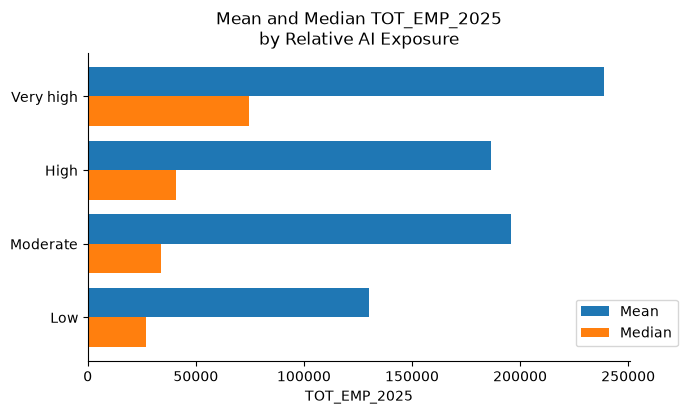

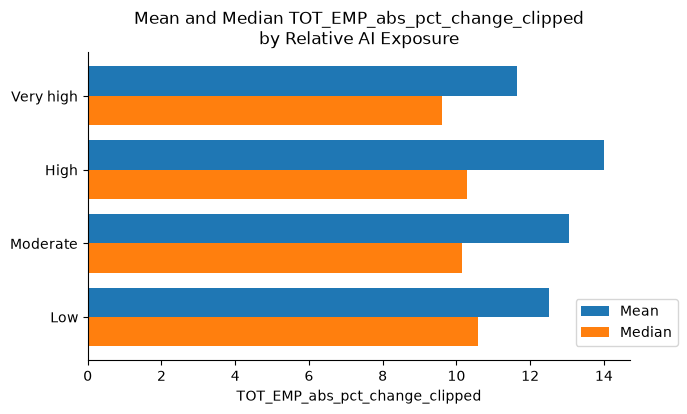

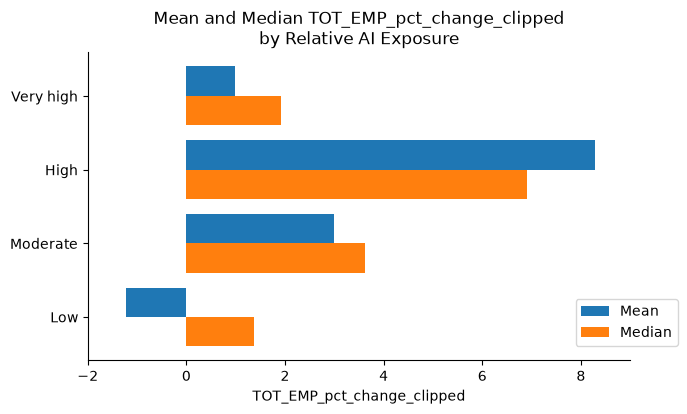

In [24]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

for col in ['TOT_EMP_2025', 'TOT_EMP_abs_pct_change_clipped', 'TOT_EMP_pct_change_clipped']:
    means = merged_data.groupby('Relative AI exposure')[col].mean().loc[reversed(exposure_ordering)]
    medians = merged_data.groupby('Relative AI exposure')[col].median().loc[reversed(exposure_ordering)]
    plt.figure(figsize=(7, 4))
    width = 0.4
    plt.barh([i + width/2 for i in range(len(medians))], means, height=width, label='Mean')
    plt.barh([i - width/2 for i in range(len(means))], medians, height=width, label='Median', left=0)
    plt.title(f"Mean and Median {col}\nby Relative AI Exposure")
    plt.xlabel(col)
    # plt.ylabel('Relative AI Exposure')
    plt.yticks([i for i in range(len(means))], means.index)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.legend(loc='lower right', bbox_to_anchor=(1.1, 0.025))
    if col == 'TOT_EMP_pct_change_clipped':
        plt.xlim(-2, 9)

    plt.show()

So the main two takeaways from the plots are these:
1. The occupations in the 'Very high' category do tend to be quite a bit larger than those in the other categories.
2. There seems to be less change in the occupations with high exposure than those in other categories. This is kind of the exact opposite of what I had gone in thinking. The difference in occupation size between the exposure categories is large enough that I'm wondering if that's part of the explanation, or if there has just actually been less volatility in those groups.

## Readiness

12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?

    The data is basically ready to go. Outliers have been handled, all columns needed for the analysis are already there,

13. What analyses is this dataset ready to support?

    It's ready to support permutation testing for the mean value of the `TOT_EMP_abs_pct_change_clipped`, or using bootstrapping to quantify the uncertainty of the estimates for each group.

## Other questions prompted by this dataset

Some of these questions were already raised and addressed earlier in the dataset.

The first one was about which level of granularity the analysis should be done at. And looking at the AI Exposure data set, it was clear that going up a level of aggregation would mean combining many occupations with different exposure ratings into the same group, and so I would be losing a lot of information by doing this.

Another question was just about verifying that the AI Exposure dataset and the historical employement data were being measured at the same level of granularity and classified the same way. I verified it by making sure it was a 1-to-1 merge, with no duplicates, and that the occupation labels matched after merging on the occupation codes. And I also verified that the employment numbers were at least within the same ballpark, to make sure I was understanding the data correctly.

The final question prompted sort of arose from my EDA earlier, where I noticed that the 'Very High' exposure group tended to have much larger occupations, and also saw less volatility than other categories. So I wanted to explore that relationship, to see if it was just that larger occupations tended to have less volatility, or if there seemed to be something systematic happening where occupations with very high exposure were seeing less volatility. I sort of briefly try to explore that below. and it paints a muddled picture. It might warrant a bit more digging, but nothing stands out immediately.

### Looking at abs percent change in employment by relative AI exposure, broken down by quartiles of total employment in 2025

I basically break the occupations into quartiles based on their total employment in 2025 and then look at the absolute percent change in employment by relative AI exposure within each quartile. So the goal is that I'll be comparing occupations of similiar sizes across the exposure categories, and thereby kind of controlling for the effect of occupation size on the observed changes.

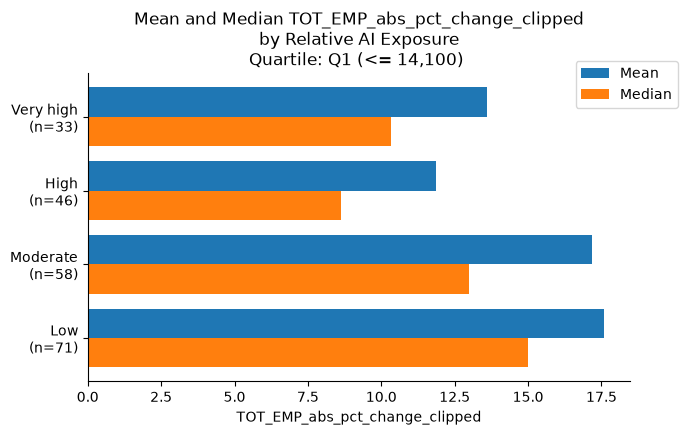

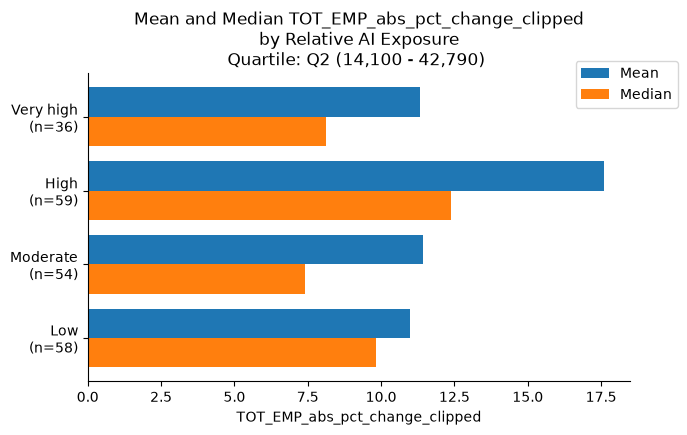

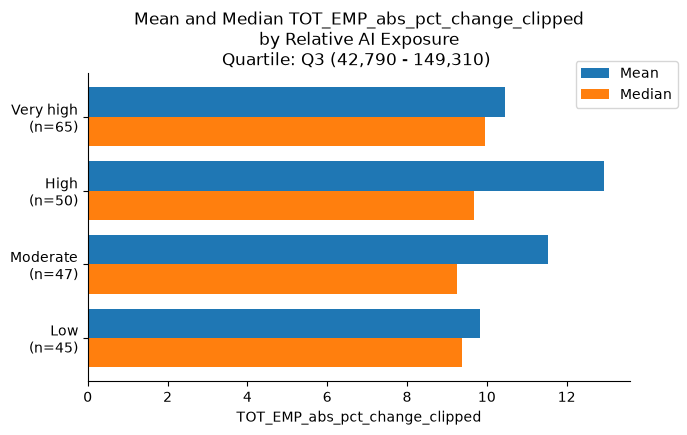

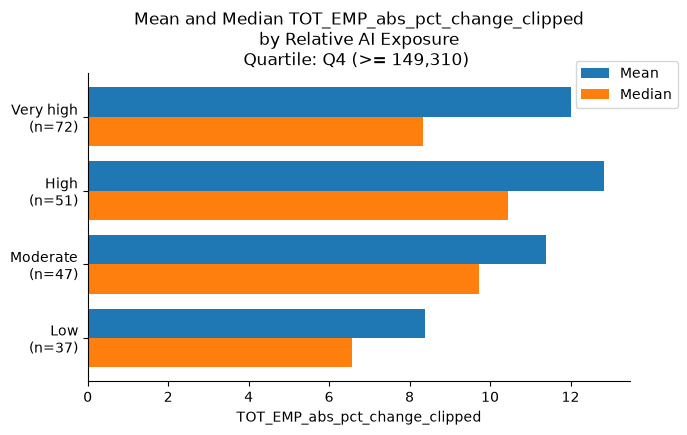

In [25]:
exposure_ordering = ['Very high', 'High', 'Moderate', 'Low']

# add the quartile cutoff points to the title of each plot
quartiles = merged_data['TOT_EMP_2025'].quantile([0.25, 0.5, 0.75])
quartile_labels = ['Q1', 'Q2', 'Q3', 'Q4']
merged_data['TOT_EMP_2025_quartile'] = pd.cut(
    merged_data['TOT_EMP_2025'],
    bins=[-float('inf')] + list(quartiles) + [float('inf')],
    labels=quartile_labels
)
for quartile in quartile_labels:
    filtered_data = merged_data[merged_data['TOT_EMP_2025_quartile'] == quartile]
    for col in ['TOT_EMP_abs_pct_change_clipped']:
        means = (filtered_data.groupby('Relative AI exposure')[col].mean()
                 .loc[reversed(exposure_ordering)])
        medians = (filtered_data.groupby('Relative AI exposure')[col].median()
                   .loc[reversed(exposure_ordering)])
        plt.figure(figsize=(7, 4))
        width = 0.4
        plt.barh([i + width/2 for i in range(len(medians))],
                  means, height=width, label='Mean')
        plt.barh([i - width/2 for i in range(len(means))],
                  medians, height=width, label='Median', left=0)
        # add the quartile cutoff points to the title of each plot
        quartile_cutoffs = {
            'Q1': f"<= {quartiles[0.25]:,.0f}",
            'Q2': f"{quartiles[0.25]:,.0f} - {quartiles[0.5]:,.0f}",
            'Q3': f"{quartiles[0.5]:,.0f} - {quartiles[0.75]:,.0f}",
            'Q4': f">= {quartiles[0.75]:,.0f}"
        }
        plt.title(f"Mean and Median {col}\nby Relative AI Exposure\nQuartile: "
                  f"{quartile} ({quartile_cutoffs[quartile]}) ")
        plt.xlabel(col)
        # add num observations for each Relative AI exposure category to the tick labels
        counts = (filtered_data.groupby('Relative AI exposure')[col].count()
                  .loc[reversed(exposure_ordering)])
        plt.yticks([i for i in range(len(means))],
                    [f"{idx}\n(n={counts[idx]})" for idx in means.index])
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.legend(loc='upper right', bbox_to_anchor=(1.1, 1.0625))
        plt.show()

That's the end of the EDA!